In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sqlalchemy import create_engine
import psycopg2
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import MinMaxScaler, OneHotEncoder
from sklearn.model_selection import train_test_split
from sklearn.linear_model import SGDClassifier, LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.metrics import accuracy_score, root_mean_squared_error, confusion_matrix

In [2]:
df = pd.read_csv("neo.csv")

In [3]:
df.shape
df.columns
df.info()
df.describe()
df.isnull().sum()
df.duplicated().sum()
df

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 90836 entries, 0 to 90835
Data columns (total 10 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   id                  90836 non-null  int64  
 1   name                90836 non-null  object 
 2   est_diameter_min    90836 non-null  float64
 3   est_diameter_max    90836 non-null  float64
 4   relative_velocity   90836 non-null  float64
 5   miss_distance       90836 non-null  float64
 6   orbiting_body       90836 non-null  object 
 7   sentry_object       90836 non-null  bool   
 8   absolute_magnitude  90836 non-null  float64
 9   hazardous           90836 non-null  bool   
dtypes: bool(2), float64(5), int64(1), object(2)
memory usage: 5.7+ MB


,id,name,est_diameter_min,est_diameter_max,relative_velocity,miss_distance,orbiting_body,sentry_object,absolute_magnitude,hazardous
0,2162635,162635 (2000 SS164),1.198271,2.679415,13569.249224,5.483974e+07,Earth,False,16.73,False
1,2277475,277475 (2005 WK4),0.265800,0.594347,73588.726663,6.143813e+07,Earth,False,20.00,True
2,2512244,512244 (2015 YE18),0.722030,1.614507,114258.692129,4.979872e+07,Earth,False,17.83,False
3,3596030,(2012 BV13),0.096506,0.215794,24764.303138,2.543497e+07,Earth,False,22.20,False
4,3667127,(2014 GE35),0.255009,0.570217,42737.733765,4.627557e+07,Earth,False,20.09,True
...,...,...,...,...,...,...,...,...,...,...
90831,3763337,(2016 VX1),0.026580,0.059435,52078.886692,1.230039e+07,Earth,False,25.00,False
90832,3837603,(2019 AD3),0.016771,0.037501,46114.605073,5.432121e+07,Earth,False,26.00,False
90833,54017201,(2020 JP3),0.031956,0.071456,7566.807732,2.840077e+07,Earth,False,24.60,False
90834,54115824,(2021 CN5),0.007321,0.016370,69199.154484,6.869206e+07,Earth,False,27.80,False


In [4]:
def name_fun(name):
    n1 = name.split("(")[-1]
    return n1.split(" ")[-1]
def year_fun(name):
    n1 = name.split("(")[-1]
    return n1.split(" ")[0]

df["est_name"] = df["name"].apply(name_fun)
df["est_name"] = df["est_name"].str.replace(")", "")
df["year"] = df["name"].apply(year_fun)
df["mean_dimeter"] = (df["est_diameter_max"] + df["est_diameter_min"])/2
df["diameter_range"] = df["est_diameter_max"] - df["est_diameter_min"]
df["kenitic_energy_proxy"] = (df["mean_dimeter"] ** 2) * (df["relative_velocity"] ** 2)
df["distance_velocity_ratio"] = df["miss_distance"] / df["relative_velocity"]
df["log_miss_distance"] = np.log(1 + df["miss_distance"])
def d_category(mean_dimeter):
    if mean_dimeter < 0.14:
        return "Small"
    else:
        return "Large"
def ve_category(relative_velocity):
    if relative_velocity < 10000:
        return "Low"
    elif relative_velocity >= 10000 and relative_velocity < 25000:
        return "Medium"
    else:
        return "Hight"
def ma_category(absolute_magnitude):
    if absolute_magnitude <= 22:
        return "Breghter_Large"
    else:
        return "Fainter_Smaller"
df["distance_category"] = df["mean_dimeter"].apply(d_category)
df["velocity_category"] = df["relative_velocity"].apply(ve_category)
df["magnitude_category"] = df["absolute_magnitude"].apply(ma_category)
df.columns = df.columns.str.lower()
df = df.rename(columns={"id":"Id"})
     

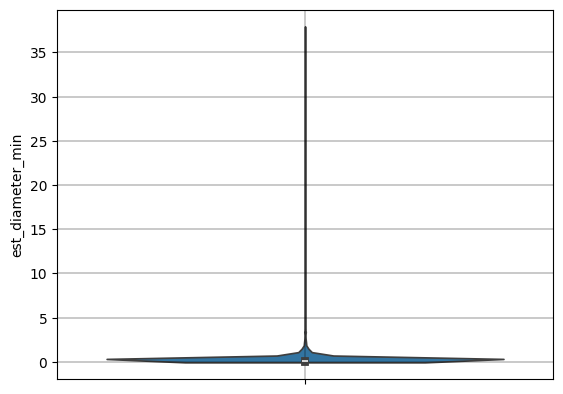

In [5]:
sns.violinplot(df["est_diameter_min"])
plt.grid(color="black", linewidth=0.3)

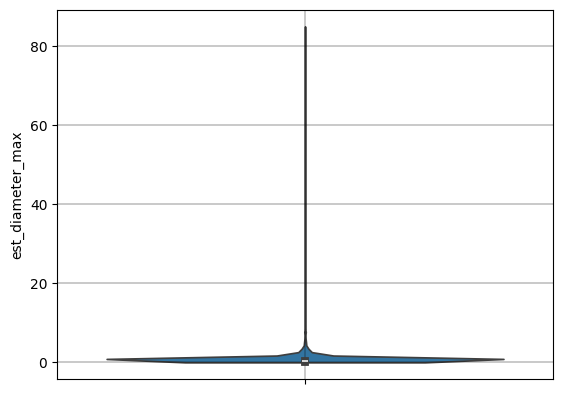

In [6]:
sns.violinplot(df["est_diameter_max"])
plt.grid(color="black", linewidth=0.3)

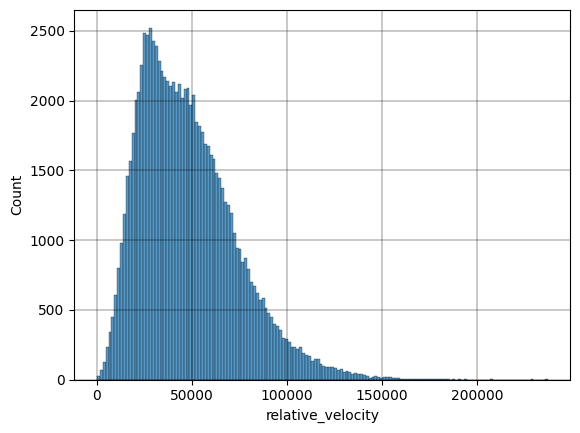

In [7]:
sns.histplot(df["relative_velocity"])
plt.grid(color="black", linewidth=0.3)

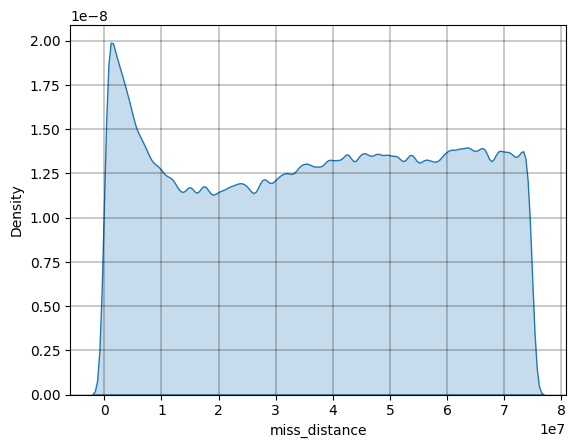

In [8]:
sns.kdeplot(df["miss_distance"], fill=True, levels=6, bw_adjust=0.3)
plt.grid(color="black", linewidth=0.3)

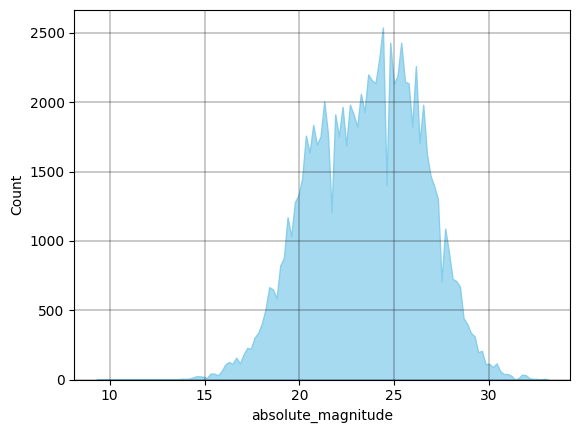

In [9]:
sns.histplot(df["absolute_magnitude"], color="skyblue", element="poly")
plt.grid(color="black", linewidth=0.3)

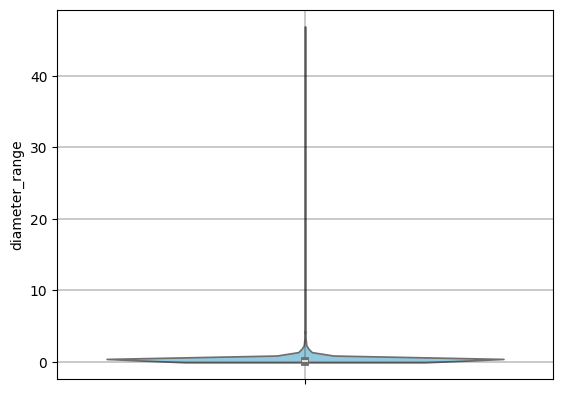

In [10]:
sns.violinplot(df["diameter_range"], color="skyblue")
plt.grid(color="black", linewidth=0.3)

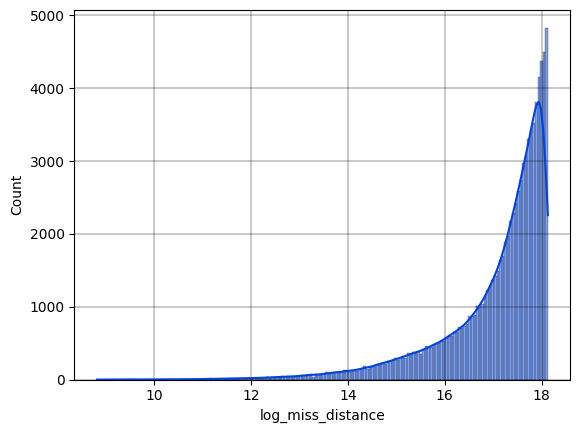

In [11]:
sns.histplot(df["log_miss_distance"], color="#0043DFC8", kde=True)
plt.grid(color="black", linewidth=0.3)

C:\Users\USER\AppData\Local\Temp\ipykernel_12512\4137524373.py:1: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x="distance_category", palette="Set2")


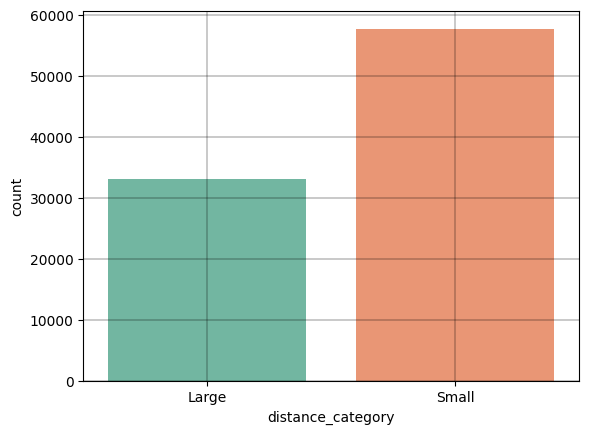

In [12]:
sns.countplot(data=df, x="distance_category", palette="Set2")
plt.grid(color="black", linewidth=0.3)

C:\Users\USER\AppData\Local\Temp\ipykernel_12512\4137524373.py:1: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x="distance_category", palette="Set2")


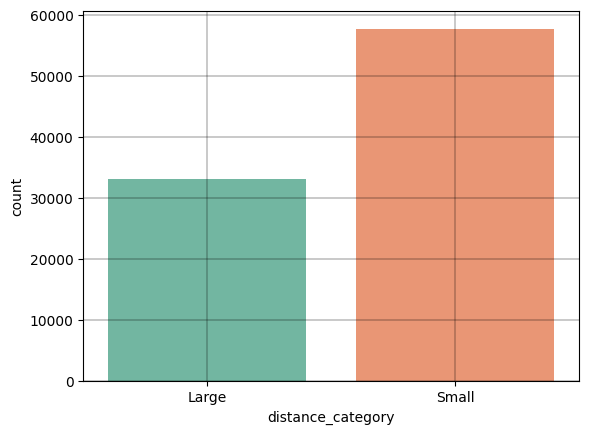

In [13]:
sns.countplot(data=df, x="distance_category", palette="Set2")
plt.grid(color="black", linewidth=0.3)

C:\Users\USER\AppData\Local\Temp\ipykernel_12512\236516668.py:1: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x="magnitude_category", palette="Set2")


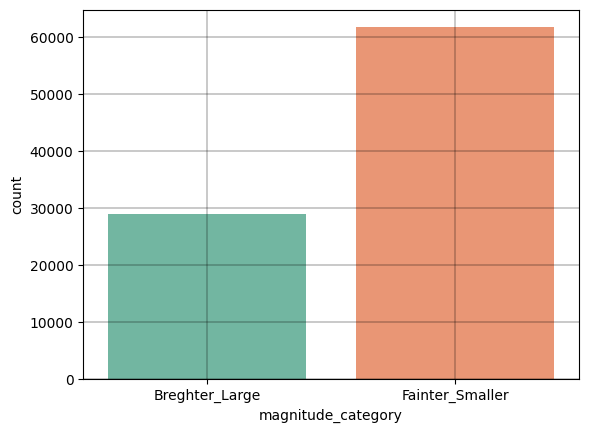

In [14]:
sns.countplot(data=df, x="magnitude_category", palette="Set2")
plt.grid(color="black", linewidth=0.3)

<Axes: xlabel='mean_dimeter', ylabel='absolute_magnitude'>

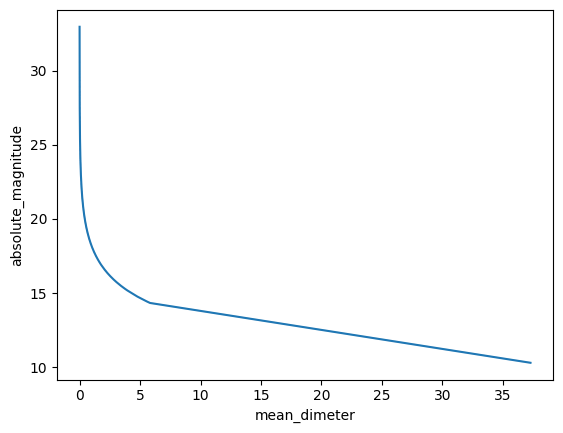

In [15]:
df1 = df.sample(9000)
sns.lineplot(x = df1["mean_dimeter"], y=df1["absolute_magnitude"], estimator="mean")

In [16]:
train_val_df, test_df = train_test_split(df, random_state=42, test_size=0.2)
train_df, val_df = train_test_split(train_val_df, random_state=42, test_size=0.25)

In [17]:
print(train_df.shape)
print(val_df.shape)
print(test_df.shape)

(54501, 20)
(18167, 20)
(18168, 20)


In [18]:
input_columns = ["est_diameter_min", "est_diameter_max", "relative_velocity", "miss_distance", "absolute_magnitude", "est_name",	"year",	"mean_dimeter",	"diameter_range",	"kenitic_energy_proxy",	"distance_velocity_ratio",	"log_miss_distance",	"distance_category",	"velocity_category", "magnitude_category"]
target_column = ["hazardous"]
train_inputs = train_df[input_columns]
val_inputs = val_df[input_columns]
test_inputs = test_df[input_columns]
train_target = train_df[target_column]
val_target = val_df[target_column]
test_target = test_df[target_column]
num_columns = train_inputs.select_dtypes(include=np.number).columns.tolist()
cat_columns = train_inputs.select_dtypes("object").columns.tolist()
scaler = MinMaxScaler()
scaler.fit(train_df[num_columns])
train_inputs[num_columns] = scaler.transform(train_inputs[num_columns])
val_inputs[num_columns] = scaler.transform(val_inputs[num_columns])
test_inputs[num_columns] = scaler.transform(test_inputs[num_columns])
enc = OneHotEncoder(handle_unknown="ignore")
enc.fit(train_df[["distance_category"]])
new_colmuns = enc.get_feature_names_out(["distance_category"]).tolist()
train_inputs[new_colmuns] = enc.transform(train_inputs[["distance_category"]]).toarray()
val_inputs[new_colmuns] = enc.transform(val_inputs[["distance_category"]]).toarray()
test_inputs[new_colmuns] = enc.transform(test_inputs[["distance_category"]]).toarray()

C:\Users\USER\AppData\Local\Temp\ipykernel_12512\3253193781.py:13: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  train_inputs[num_columns] = scaler.transform(train_inputs[num_columns])
C:\Users\USER\AppData\Local\Temp\ipykernel_12512\3253193781.py:14: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  val_inputs[num_columns] = scaler.transform(val_inputs[num_columns])
C:\Users\USER\AppData\Local\Temp\ipykernel_12512\3253193781.py:15: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from 

In [19]:
x_train = train_inputs[num_columns + new_colmuns]
x_val = val_inputs[num_columns + new_colmuns]

In [20]:
model = LogisticRegression(random_state=42, n_jobs=-1, max_iter=300)
model.fit(x_train, train_target)

C:\Users\USER\AppData\Roaming\Python\Python310\site-packages\sklearn\utils\validation.py:1406: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)


,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,None
,random_state,42
,solver,'lbfgs'
,max_iter,300
,multi_class,'deprecated'


In [21]:
preds = model.predict(x_train)
accuracy_score(preds, train_target)

0.9077631603089852

In [22]:
accuracy_score(model.predict(x_val), val_target)

0.9104420102383443

<Axes: >

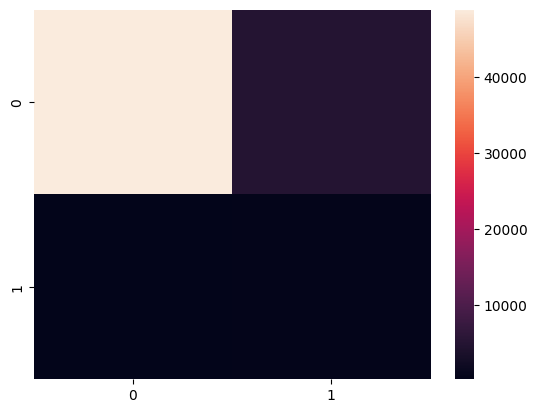

In [23]:
def model1_heat_map(cm):
    return sns.heatmap(cm, annot=False)
model1_heat_map(confusion_matrix(preds, train_target))


<Axes: >

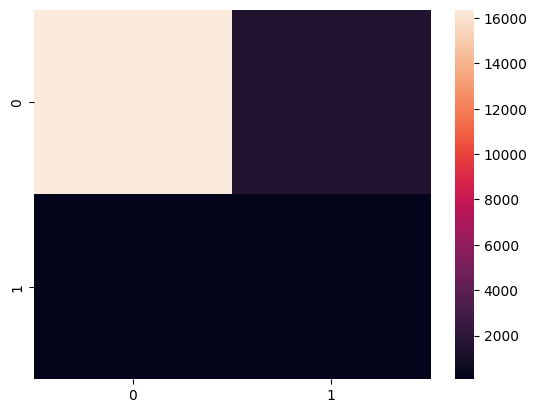

In [24]:
model1_heat_map(confusion_matrix(model.predict(x_val), val_target))

In [25]:
model2 = DecisionTreeClassifier(random_state=42, criterion="log_loss", max_depth=5, min_samples_split=8, max_features=30)
model2.fit(x_train ,train_target)

,criterion,'log_loss'
,splitter,'best'
,max_depth,5
,min_samples_split,8
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,30
,random_state,42
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,class_weight,None


In [26]:
accuracy_score(model.predict(x_train), train_target)

0.9077631603089852

In [27]:
accuracy_score(model.predict(x_val), val_target)

0.9104420102383443

In [28]:
def best_hy_params(hp):
    m1 = DecisionTreeClassifier(random_state=42, criterion="log_loss", max_depth=hp)
    m1.fit(x_train, train_target)
    train_error = 1 - accuracy_score(m1.predict(x_train), train_target)
    val_error = 1 - accuracy_score(m1.predict(x_val), val_target)
    return {"hp": hp, "train_error":train_error, "val_error":val_error}
max_depths_df = pd.DataFrame([best_hy_params(hp) for hp in range(2, 30)])

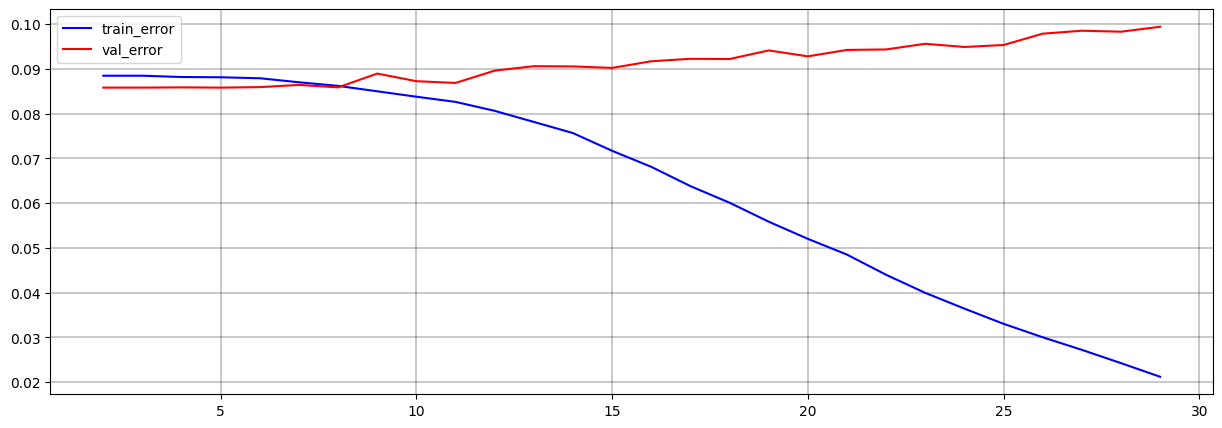

In [29]:

plt.figure(figsize=(15, 5))
plt.plot(max_depths_df["hp"], max_depths_df["train_error"], color="blue")
plt.plot(max_depths_df["hp"], max_depths_df["val_error"], color="red")
plt.legend(["train_error", "val_error"])
plt.grid(axis="both", linewidth=0.3, color="black")
plt.show()


In [30]:
max_depths_df[max_depths_df["val_error"] == max_depths_df["val_error"].describe().loc["min"]][["hp", "val_error"]]

,hp,val_error
0,2,0.085815
1,3,0.085815
3,5,0.085815


In [31]:
def hp_table(df):
    return df[df["val_error"] == df["val_error"].describe().loc["min"]][["hp", "val_error"]]

In [32]:
def best_hy_param(hp):
    m2 = DecisionTreeClassifier(random_state=42, criterion="log_loss", max_depth=5, min_samples_split=hp)
    m2.fit(x_train, train_target)
    train_error = 1 - accuracy_score(m2.predict(x_train), train_target)
    val_error = 1 - accuracy_score(m2.predict(x_val), val_target)
    return {"hp": hp, "train_error":train_error, "val_error":val_error}
mss_df = pd.DataFrame([best_hy_param(hp) for hp in range(2, 30)])


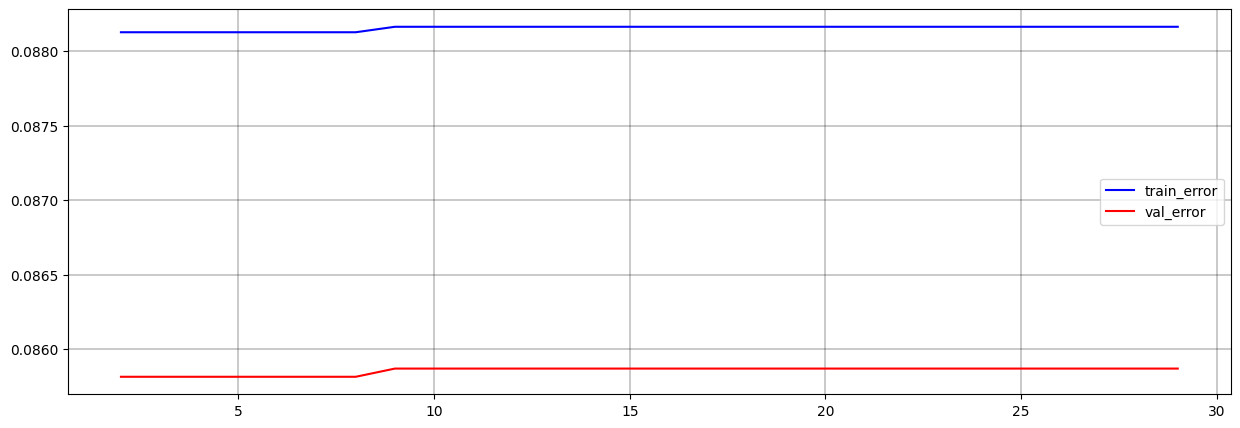

In [33]:
plt.figure(figsize=(15, 5))
plt.plot(mss_df["hp"], mss_df["train_error"], color="blue")
plt.plot(mss_df["hp"], mss_df["val_error"], color="red")
plt.legend(["train_error", "val_error"])
plt.grid(axis="both", linewidth=0.3, color="black")
plt.show()

In [34]:
def best_hy_param(hp):
    m2 = DecisionTreeClassifier(random_state=42, criterion="log_loss", max_depth=5, min_samples_split=hp)
    m2.fit(x_train, train_target)
    train_error = 1 - accuracy_score(m2.predict(x_train), train_target)
    val_error = 1 - accuracy_score(m2.predict(x_val), val_target)
    return {"hp": hp, "train_error":train_error, "val_error":val_error}
mss_df = pd.DataFrame([best_hy_param(hp) for hp in range(2, 30)])

In [35]:
model3 = RandomForestClassifier(n_jobs=-1, random_state=42, n_estimators=200)
model3.fit(x_train, train_target)

C:\Users\USER\AppData\Roaming\Python\Python310\site-packages\sklearn\base.py:1365: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using ravel().
  return fit_method(estimator, *args, **kwargs)


,n_estimators,200
,criterion,'gini'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,'sqrt'
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


In [36]:
accuracy_score(model.predict(x_train), train_target)

0.9077631603089852

In [37]:
accuracy_score(model.predict(x_val), val_target)

0.9104420102383443

In [ ]:
model4 = XGBClassifier(random_state=42, n_jobs=-1, n_estimators=232, learning_rate=0.03, min_child_weight=3, colsample_bytree=0.8, 
    eva_metric="logloss", tree_method="hist")

model4.fit(x_train, train_target)

C:\Users\USER\AppData\Roaming\Python\Python310\site-packages\xgboost\training.py:200: UserWarning: [15:12:00] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\learner.cc:782: 
Parameters: { "eva_metric" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)


,objective,'binary:logistic'
,base_score,None
,booster,None
,callbacks,None
,colsample_bylevel,None
,colsample_bynode,None
,colsample_bytree,0.8
,device,None
,early_stopping_rounds,None
,enable_categorical,False
,eval_metric,None


In [80]:
accuracy_score(model4.predict(x_train), train_target)

0.9150657786095668

In [81]:
accuracy_score(model4.predict(x_val), val_target)

0.915120823471129

In [41]:
def best_hy_param_xg(hp):
    m3 = XGBClassifier(random_state=42, n_jobs=-1, 	n_estimators=hp)
    m3.fit(x_train, train_target)
    train_error = 1 - accuracy_score(m3.predict(x_train), train_target)
    val_error = 1 - accuracy_score(m3.predict(x_val), val_target)
    return {"hp": hp, "train_error":train_error, "val_error":val_error}
n_est_df = pd.DataFrame([best_hy_param_xg(hp) for hp in range(200, 300)])

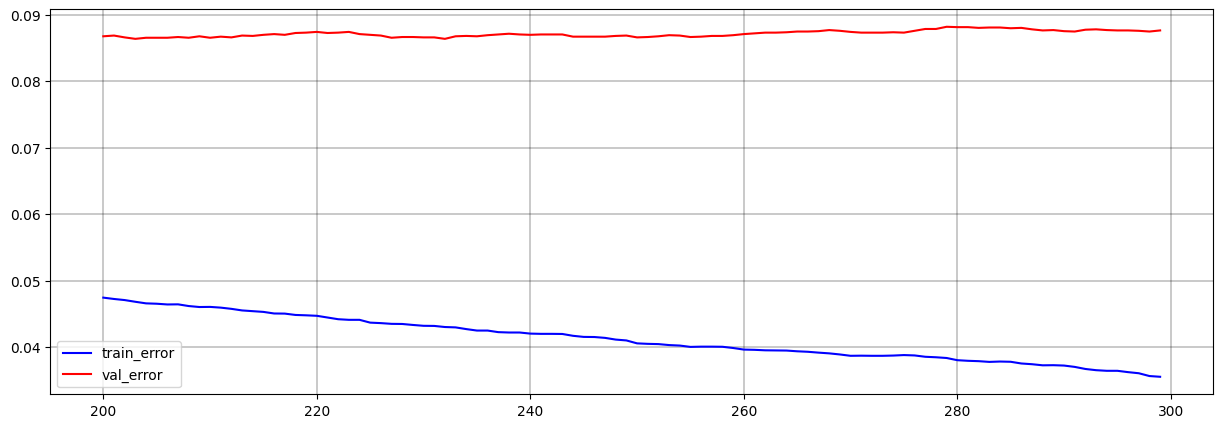

In [42]:
plt.figure(figsize=(15, 5))
plt.plot(n_est_df["hp"], n_est_df["train_error"], color="blue")
plt.plot(n_est_df["hp"], n_est_df["val_error"], color="red")
plt.legend(["train_error", "val_error"])
plt.grid(axis="both", linewidth=0.3, color="black")
plt.show()

In [43]:
n_est_df[n_est_df["val_error"] == n_est_df["val_error"].describe().loc["min"]][["hp", "val_error"]]

,hp,val_error
3,203,0.086365
32,232,0.086365


In [88]:
def model_prdection(inputs, target): 
    ml_model = XGBClassifier(random_state=42, n_jobs=-1, n_estimators=232, learning_rate=0.03, min_child_weight=3,
     colsample_bytree=0.8, tree_method="hist")
    ml_model.fit(inputs, target)
    return accuracy_score(ml_model.predict(inputs), target), ml_model.predict(inputs)

In [91]:
model_prdection(x_val, val_target)

(0.9174877525183024, array([0, 0, 0, ..., 0, 0, 0], shape=(18167,)))